# ST1131 Introduction to Statistics and Statistical Computing
## Topic 5 (Random Variables)

In the lecture, we learnt what random variables are and how their probability distributions, means and variances are defined. In this notebook, we will learn how to compute and visualise them in Python. We will represent discrete distributions using `numpy` and `pandas`, work with the binomial, Poisson and normal distributions using `scipy.stats`, and use simulation to check some of the properties from the lecture.

## Packages

Besides `numpy`, `pandas` and `matplotlib`, we will now use `scipy`. The `scipy.stats` module contains many probability distributions, and we will selectively import the few that we need: `bernoulli`, `binom`, and `norm`. We also import `math` again for a few formulas.

In [21]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import bernoulli, binom, norm

Several parts of this notebook simulate random experiments. We create a fixed seed (here `1131`) so that the "random" results are the same every time the notebook is run from top to bottom. If you change the seed, the numbers will change slightly, but the conclusions will not.

In [22]:
np.random.seed(1131)

## Using scipy.stats

For well-known distributions, we do not need to type in the probabilities by hand. Each distribution in `scipy.stats` comes with the same set of functions:

| Function | Meaning |
|---|---|
| `.pmf(x, ...)` | $P(X=x)$, for discrete distributions only |
| `.pdf(x, ...)` | height of the density curve $f(x)$, for continuous distributions only |
| `.cdf(x, ...)` | $P(X\le x)$, the area to the left |
| `.sf(x, ...)` | $P(X>x)=1-P(X\le x)$, the area to the right |
| `.ppf(q, ...)` | the value $x$ such that $P(X\le x)=q$, which is a quantile |
| `.mean()`, `.var()`, `.std()` | $\mu$, $\sigma^2$ and $\sigma$ |
| `.rvs(..., size=)` | random draws for simulation |

The `...` stands for the parameters of the distribution, which differ from one distribution to another. 

For $X\sim Bin(n,p)$, we use `binom.pmf(x, n, p)`. 

For $X\sim N(\mu,\sigma^2)$, we use `norm.pdf(x, loc=mu, scale=sigma)`.

### Caution with the normal distribution

In `norm`, the `scale` argument is the standard deviation $\sigma$, not the variance $\sigma^2$. The lecture writes $N(\mu,\sigma^2)$, so for $X\sim N(80,144)$ we must use `scale=12` and not `scale=144`. Always take the square root first.

## Binomial distribution

If $X\sim Bin(n,p)$, then $P(X=x)=C^n_x\,p^x(1-p)^{n-x}$ for $x=0,1,\dots,n$, with $E(X)=np$ and $Var(X)=np(1-p)$.

### DNA sequence alignment

Two DNA sequences of length 10 are compared, and each position matches with probability 0.25 independently, so the number of matches is $X\sim Bin(10,0.25)$. The function `math.comb(n, x)` computes $C^n_x=\frac{n!}{x!(n-x)!}$, so we can use the formula directly and compare it with `binom.pmf`.

In [23]:
n = 10
p = 0.25

#For P(X=5)
by_formula = math.comb(n, 5) * p**5 * (1-p)**5
by_scipy = binom.pmf(5, n, p)

print(f"P(X=5) by formula: {round(by_formula, 4)}")
print(f"P(X=5) by scipy: {round(by_scipy, 4)}")

P(X=5) by formula: 0.0584
P(X=5) by scipy: 0.0584


We can also get the whole distribution in one table.

In [24]:
x_dna = np.arange(0, n+1)
dna = pd.DataFrame({"x": x_dna, "P(X=x)": binom.pmf(x_dna, n, p)})
print(dna.round(4))

     x  P(X=x)
0    0  0.0563
1    1  0.1877
2    2  0.2816
3    3  0.2503
4    4  0.1460
5    5  0.0584
6    6  0.0162
7    7  0.0031
8    8  0.0004
9    9  0.0000
10  10  0.0000


### Probabilities of "at least" and "at most"

Let's say we want $P(X\ge5)$. There are three equivalent ways to get it. We can manually add up $P(X=5)+P(X=6)+\dots+P(X=10)$, use the complement $1-P(X\le4)$, or solve the reverse of that which gives $P(X>4)$, the same as $P(X\ge5)$.

In [25]:
way1 = binom.pmf(np.arange(5,11), n, p).sum()
way2 = 1 - binom.cdf(4, n, p)
way3 = binom.sf(4, n, p)

print(round(way1, 4))
print(round(way2, 4))
print(round(way3, 4))

0.0781
0.0781
0.0781


### Caution with discrete variables

For a discrete variable, $P(X\ge5)$ is not `1-binom.cdf(5, n, p)`. That would give $P(X>5)$, which leaves out $P(X=5)$. Since $X$ only takes whole numbers, "at least 5" means "more than 4", so we use 4. This issue does not arise for continuous variables, where $P(X=x)=0$.

### Mean and variance

We can compare $np$ and $np(1-p)$ with the built-in functions.

In [26]:
print(f"np: {n*p}, vs binom.mean: {binom.mean(n, p)}")
print(f"np(1-p): {n*p*(1-p)}, vs binom.var: {binom.var(n, p)}")

np: 2.5, vs binom.mean: 2.5
np(1-p): 1.875, vs binom.var: 1.875


We can also confirm these by simulation. The function `binom.rvs` draws random values from the distribution, so here we repeat the DNA experiment 100,000 times.

In [27]:
sim = binom.rvs(n, p, size=100000)
print(f"Simulated mean: {round(sim.mean(), 4)}")
print(f"Simulated variance: {round(sim.var(), 4)}")

Simulated mean: 2.5027
Simulated variance: 1.8632


### Bar plots of binomial distributions

Here are two examples, seed germination $Z\sim Bin(20,0.6)$ and breast cancer $Y\sim Bin(50,1/9)$.

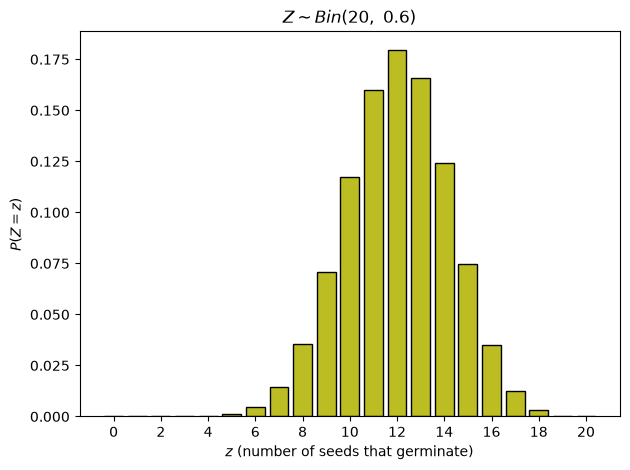

In [28]:
z_seed = np.arange(0,21)

plt.figure()
plt.bar(z_seed, binom.pmf(z_seed, 20, 0.6), color="tab:olive", edgecolor="black")
plt.xticks(range(0,21,2))
plt.xlabel(r"$z$ (number of seeds that germinate)")
plt.ylabel(r"$P(Z=z)$")
plt.title(r"$Z\sim Bin(20,\ 0.6)$")
plt.tight_layout()
plt.show()

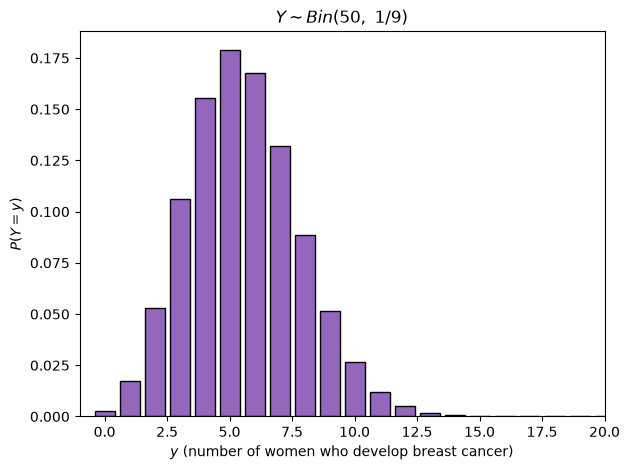

In [29]:
y_bc = np.arange(0,51)

plt.figure()
plt.bar(y_bc, binom.pmf(y_bc, 50, 1/9), color="tab:purple", edgecolor="black")
plt.xlim(-1,20) #probabilities beyond 20 are practically 0
plt.xlabel(r"$y$ (number of women who develop breast cancer)")
plt.ylabel(r"$P(Y=y)$")
plt.title(r"$Y\sim Bin(50,\ 1/9)$")
plt.tight_layout()
plt.show()

A Bernoulli distribution is simply $Bin(1,p)$, a single trial that is either a success (1) or a failure (0).

In [30]:
#P(failure) = 0.4, P(success) = 0.6
print("Using binom, P(X=0) = ", binom.pmf(0, 1, 0.6))
print("Using binom, P(X=1) = ", binom.pmf(1, 1, 0.6))
print("Using bernoulli, P(X=0) = ", bernoulli.pmf(0, 0.6))
print("Using bernoulli, P(X=1) = ", bernoulli.pmf(1, 0.6))

Using binom, P(X=0) =  0.4000000000000001
Using binom, P(X=1) =  0.6
Using bernoulli, P(X=0) =  0.4000000000000001
Using bernoulli, P(X=1) =  0.6


## Normal distribution

### Effect of the mean and variance

The mean $\mu$ controls where the curve is centred, and the variance $\sigma^2$ controls how spread out it is. A larger variance gives a flatter and wider curve, since the total area must still be 1.

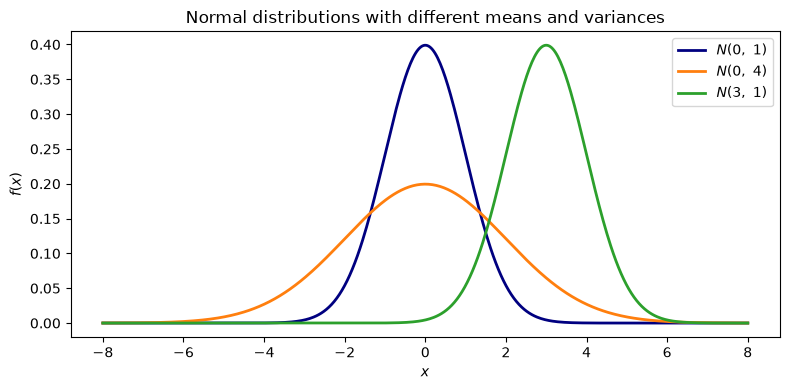

In [31]:
xs=np.linspace(-8,8,500)

plt.figure(figsize=(8,4))
plt.plot(xs, norm.pdf(xs, 0, 1), color="navy", linewidth=2, label=r"$N(0,\ 1)$")
plt.plot(xs, norm.pdf(xs, 0, 2), color="tab:orange", linewidth=2, label=r"$N(0,\ 4)$")
plt.plot(xs, norm.pdf(xs, 3, 1), color="tab:green", linewidth=2, label=r"$N(3,\ 1)$")
plt.xlabel(r"$x$")
plt.ylabel(r"$f(x)$")
plt.title("Normal distributions with different means and variances")
plt.legend()
plt.tight_layout()
plt.show()

### Finding probabilities

Let us assume that we are interested in the normal distribution $X\sim N(80,144)$, so $\mu=80$ and $\sigma=\sqrt{144}=12$.

To draw a smooth curve, we evaluate `norm.pdf` at many closely spaced points. The function `np.linspace(start, stop, num)` creates `num` evenly spaced numbers from `start` to `stop`, including both ends.

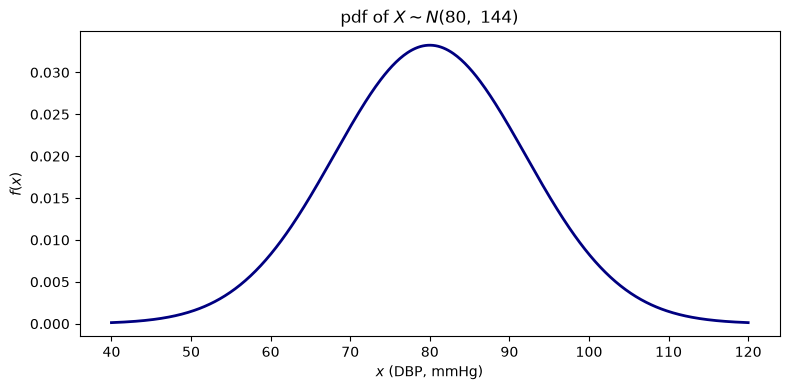

In [32]:
mu = 80
sigma = 12
xs=np.linspace(40,120,500)
fx=norm.pdf(xs, loc=mu, scale=sigma)

plt.figure(figsize=(8,4))
plt.plot(xs, fx, color="navy", linewidth=2)
plt.xlabel(r"$x$ (DBP, mmHg)")
plt.ylabel(r"$f(x)$")
plt.title(r"pdf of $X\sim N(80,\ 144)$")
plt.tight_layout()
plt.show()

Let's say that we are interested in $P(60\le X\le73)$. This is the area between 60 and 73, which we can find as $P(X\le73)-P(X\le60)$ using `norm.cdf`. If we are interested in $P(X\ge90)$, we use `norm.sf`, which is the same as `1-norm.cdf(90, mu, sigma)`.

In [33]:
mu = 80
sigma = 12
prob_between = norm.cdf(73, mu, sigma)-norm.cdf(60, mu, sigma)
prob_above = norm.sf(90, mu, sigma)

print("For X ~ N(80, 12^2):")
print(f"P(60 <= X <= 73): {round(prob_between, 3)}")
print(f"P(X >= 90): {round(prob_above, 3)}")

For X ~ N(80, 12^2):
P(60 <= X <= 73): 0.232
P(X >= 90): 0.202


We can shade the region under a curve with `plt.fill_between`, which is a nice way to see the probability. The `where` argument takes a condition that decides which part of the curve is shaded. You do not need to learn how to do this for this course. It is meant to help you visualise, which you can sketch out on your own if needed.

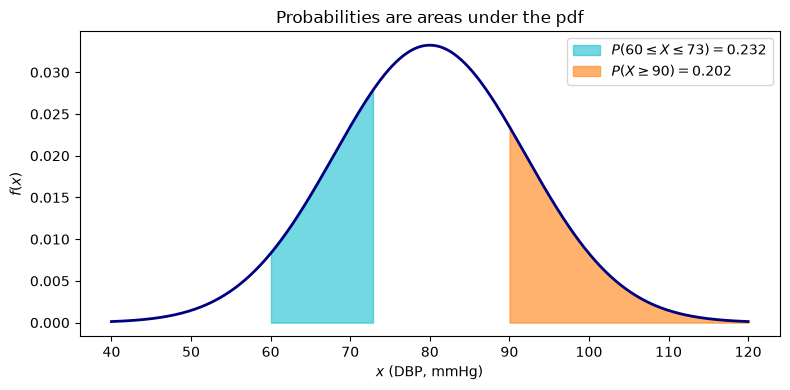

In [34]:
plt.figure(figsize=(8,4))
plt.plot(xs, fx, color="navy", linewidth=2)
plt.fill_between(xs, fx, where=(xs>=60) & (xs<=73), color="tab:cyan", alpha=0.6, label=r"$P(60\leq X\leq 73)=0.232$")
plt.fill_between(xs, fx, where=(xs>=90), color="tab:orange", alpha=0.6, label=r"$P(X\geq 90)=0.202$")
plt.xlabel(r"$x$ (DBP, mmHg)")
plt.ylabel(r"$f(x)$")
plt.title("Probabilities are areas under the pdf")
plt.legend()
plt.tight_layout()
plt.show()

Take note that the height of the pdf is not a probability. For example, `norm.pdf(80, 80, 12)` is about 0.033, but that is a density, not $P(X=80)$. For a continuous variable, $P(X=x)=0$ for every single value, which is also why $P(X\ge90)$ and $P(X>90)$ are the same.

### Finding quantiles

The $100p$-th quantile $q_p$ satisfies $P(X\le q_p)=p$. In Python, this is `.ppf`, which is the inverse of `.cdf`. To find out what $q_p$ gives us the cdf of 0.0478, 0.280 or 0.798, we will use `.ppf`.

In [35]:
print("P(X <= ", norm.ppf(0.0478, mu, sigma), ") = 0.0478")
print("P(X <= ", norm.ppf(0.280, mu, sigma), ") = 0.280")
print("P(X <= ", norm.ppf(0.798, mu, sigma), ") = 0.798")

P(X <=  60.00116371833801 ) = 0.0478
P(X <=  73.0059019127454 ) = 0.280
P(X <=  90.01398481790889 ) = 0.798


In summary, there are two types of questions. To find a probability (given a value $x$, find an area), we use `.cdf` for the area to the left or `.sf` for the area to the right. To find a quantile (given an area $p$, find a value on the horizontal axis), we use `.ppf`.

### Symmetry

Since the curve is symmetric about $\mu$, for $d>0$ we have $P(X\le\mu-d)=P(X\ge\mu+d)$, and $q_{1-p}=2\mu-q_p$. Let's check this with $N(80,144)$, $d=10$ and $p=0.1$.

In [36]:
mu = 80
sigma = 12
d = 10
print(norm.cdf(mu-d, mu, sigma))
print(norm.sf(mu+d, mu, sigma))

p = 0.1
print(norm.ppf(1-p, mu, sigma))
print(2*mu - norm.ppf(p, mu, sigma))

0.20232838096364308
0.20232838096364308
95.3786187865352
95.3786187865352


### Empirical rule

For any normal distribution, about 68%, 95% and 99.7% of values lie within 1, 2 and 3 standard deviations of the mean. For the standard normal $N(0,1)$, the default `loc=0` and `scale=1` can be left out.

In [37]:
for k in [1,2,3]:
    area = norm.cdf(k) - norm.cdf(-k)
    print(f"P({-k} <= Z <= {k}): {area:.4f}")

P(-1 <= Z <= 1): 0.6827
P(-2 <= Z <= 2): 0.9545
P(-3 <= Z <= 3): 0.9973


## Standardisation

If $X\sim N(\mu,\sigma^2)$, then $Z=(X-\mu)/\sigma\sim N(0,1)$. This means any normal probability can be found either directly, by giving `norm` the values of $\mu$ and $\sigma$, or after standardising, by using the standard normal. Both give the same answer.

If we have a distribution that follows $X\sim N(1500,90000)$, so $\sigma=\sqrt{90000}=300$, and we are interested in $P(X \leq 1800)$, we can always standardise the value first then solve it using $N(0, 1)$.

In [38]:
mu = 1500
sigma = np.sqrt(90000)

z = (1800 - mu) / sigma
print(f"Z-score of 1800: {z}")
print(f"P(X <= 1800) directly: {round(norm.cdf(1800, mu, sigma), 3)}")
print(f"P(X <= 1800) standardised: {round(norm.cdf(z), 3)}")

Z-score of 1800: 1.0
P(X <= 1800) directly: 0.841
P(X <= 1800) standardised: 0.841


## Normal approximation to the binomial distribution

If $n$ is moderately large and $p$ is not close to 0 or 1, then $Bin(n,p)$ can be approximated by $N(np,np(1-p))$, and the condition for a good approximation is $np(1-p)\ge5$. 

Now we compare each binomial bar plot with the normal curve that has the same mean and variance. We use `plt.subplots(1, 2)` to put two plots side by side, where `axes[0]` is the left plot and `axes[1]` is the right plot. When drawing on a subplot, the functions are slightly different, such as `ax.set_xlabel` instead of `plt.xlabel`. Again, learning to plot this is optional.

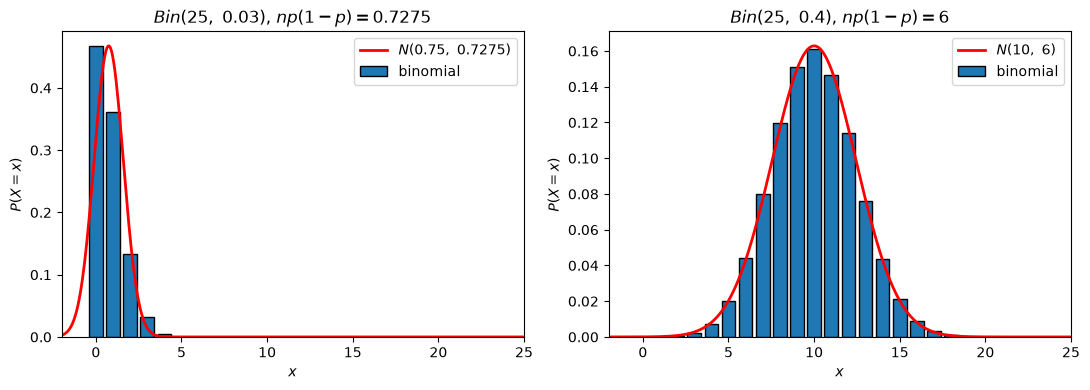

In [39]:
fig, axes=plt.subplots(1, 2, figsize=(11,4))

for ax, (n, p) in zip(axes, [(25,0.03), (25,0.4)]):
    k=np.arange(0,n+1)
    mean=n*p
    var=n*p*(1-p)
    xs=np.linspace(-2,n,400)

    ax.bar(k, binom.pmf(k, n, p), color="tab:blue", edgecolor="black", label="binomial")
    ax.plot(xs, norm.pdf(xs, mean, np.sqrt(var)), color="red", linewidth=2, label=rf"$N({mean:g},\ {var:g})$")
    ax.set_xlim(-2,25)
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$P(X=x)$")
    ax.set_title(rf"$Bin({n},\ {p})$, $np(1-p)={var:g}$")
    ax.legend()

plt.tight_layout()
plt.show()

For $Bin(25,0.03)$, the bars are piled up near 0 and heavily skewed, and the normal curve even puts some area on negative values, which is impossible for a count. For $Bin(25,0.4)$, the bars already look roughly bell-shaped and the normal curve follows them well. 

### Continuity correction

A binomial random variable $X$ is **discrete**: it only takes whole-number values $0, 1, 2, \dots$. The normal distribution is **continuous**, and for a continuous variable $Y$, $P(Y = k) = 0$ for every single value $k$. So if we approximate $X$ by $Y$ directly, we lose track of which whole numbers are included.

The fix is to treat each whole number $k$ as the interval from $k - 0.5$ to $k + 0.5$. Picture the bar plot of the binomial distribution: the bar for $x = k$ sits over exactly this interval. The normal curve should cover the same bars.

**How to apply it.** First write the event in terms of the whole numbers it includes, then extend by $0.5$ on each side so that every included bar is fully covered.

| Binomial event | Includes | Normal approximation |
|---|---|---|
| $P(X \le k)$ | $\dots, k-1, k$ | $P(Y \le k + 0.5)$ |
| $P(X < k)$ | $\dots, k-2, k-1$ | $P(Y \le k - 0.5)$ |
| $P(X \ge k)$ | $k, k+1, \dots$ | $P(Y \ge k - 0.5)$ |
| $P(X > k)$ | $k+1, k+2, \dots$ | $P(Y \ge k + 0.5)$ |
| $P(X = k)$ | $k$ only | $P(k - 0.5 \le Y \le k + 0.5)$ |

A good check: ask yourself "is $k$ itself included?" If $k$ is included, extend the boundary outward by 0.5 to take in the whole bar for $k$. If $k$ is not included, pull the boundary inward by 0.5 to leave that bar out.

**Notes**

- The continuity correction improves the approximation but does **not** rescue it when $np(1-p) < 5$. The distribution is still skewed, and a symmetric curve cannot fit it well.
- Without the correction, the normal approximation would give $P(X = k) = 0$, which is clearly wrong. With it, we get a sensible positive value.
- The correction matters less as $n$ grows, because a shift of $0.5$ becomes small compared with the standard deviation $\sqrt{np(1-p)}$.

In [40]:
n = 25
p = 0.4
mu = n*p
sigma = np.sqrt(n*p*(1-p))

print(f"Exact P(X <= 8): {round(binom.cdf(8, n, p), 4)}")
print(f"Normal, no correction: {round(norm.cdf(8, mu, sigma), 4)}")
print(f"Normal, with correction: {round(norm.cdf(8.5, mu, sigma), 4)}")

print(f"Exact P(X = 10): {round(binom.pmf(10, n, p), 4)}")
print(f"Normal, with correction: {round(norm.cdf(10.5, mu, sigma)-norm.cdf(9.5, mu, sigma), 4)}")

Exact P(X <= 8): 0.2735
Normal, no correction: 0.2071
Normal, with correction: 0.2701
Exact P(X = 10): 0.1612
Normal, with correction: 0.1617
